<a href="https://colab.research.google.com/github/belvinos91/pythonProject/blob/master/Agent_based_Modeling_MB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

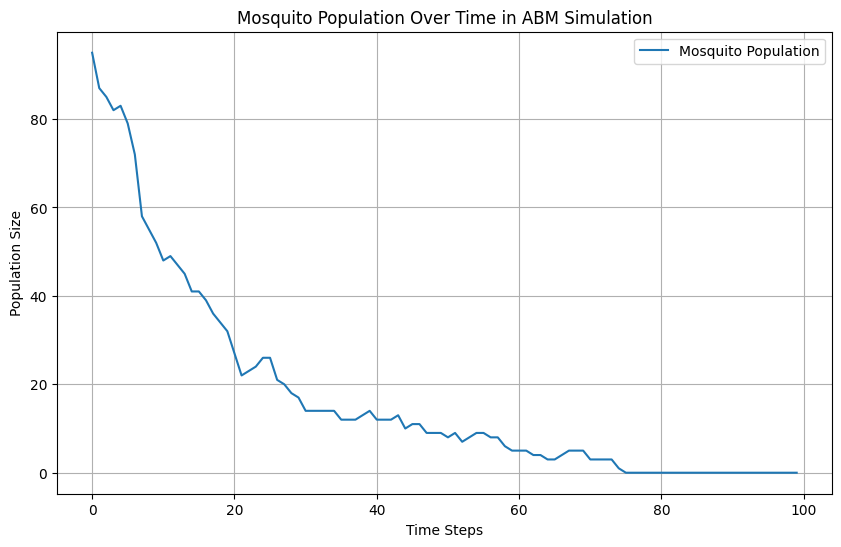

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from collections import namedtuple

# Seed for reproducibility
np.random.seed(900)

# Mosquito agent definition
class Mosquito:
    def __init__(self, age=0):
        self.age = age
        self.alive = True

    def update(self, beta, theta1, theta2):
        # Simple rules for aging and dying
        self.age += 1
        death_chance = 0.01 + 0.05 * (1 - beta)  # Increased death chance if beta is low
        if np.random.rand() < death_chance:
            self.alive = False

        # Reproduction (simplified and based on theta1 and theta2)
        if self.alive and np.random.rand() < 0.1 * theta1:
            return Mosquito()  # New mosquito born
        return None

# Environment and simulation parameters
num_initial_mosquitoes = 100
num_steps = 100  # Number of time steps in the simulation

# Initial mosquito population
mosquito_population = [Mosquito() for _ in range(num_initial_mosquitoes)]

# Placeholder for environmental factors (beta, theta1, theta2)
# These would be derived from your original model
beta = 0.03  # Example value
theta1 = 0.5  # Example value
theta2 = 0.5  # Example value

# Simulation loop
population_size_over_time = []

for step in range(num_steps):
    new_mosquitoes = []
    for mosquito in mosquito_population:
        mosquito.update(beta, theta1, theta2)
        if mosquito.alive:
            new_mosquito = mosquito.update(beta, theta1, theta2)
            if new_mosquito:
                new_mosquitoes.append(new_mosquito)

    mosquito_population.extend(new_mosquitoes)
    mosquito_population = [m for m in mosquito_population if m.alive]
    population_size_over_time.append(len(mosquito_population))

# Plotting the population size over time
plt.figure(figsize=(10, 6))
plt.plot(range(num_steps), population_size_over_time, label='Mosquito Population')
plt.xlabel('Time Steps')
plt.ylabel('Population Size')
plt.title('Mosquito Population Over Time in ABM Simulation')
plt.legend()
plt.grid(True)
plt.show()


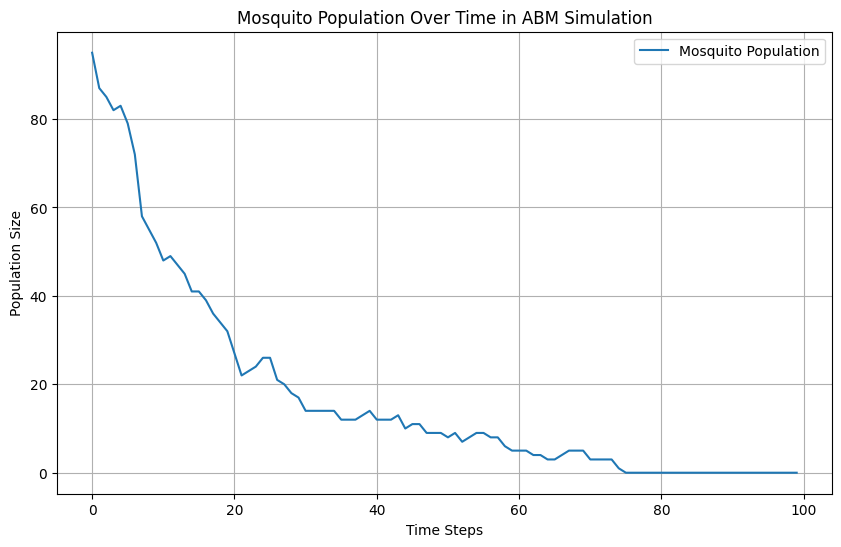

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from collections import namedtuple

# Seed for reproducibility
np.random.seed(900)

# Mosquito agent definition
class Mosquito:
    def __init__(self, age=0):
        self.age = age
        self.alive = True

    def update(self, beta, theta1, theta2):
        # Simple rules for aging and dying
        self.age += 1
        death_chance = 0.01 + 0.05 * (1 - beta)  # Increased death chance if beta is low
        if np.random.rand() < death_chance:
            self.alive = False

        # Reproduction (simplified and based on theta1 and theta2)
        if self.alive and np.random.rand() < 0.1 * theta1:
            return Mosquito()  # New mosquito born
        return None

# Environment and simulation parameters
num_initial_mosquitoes = 100
num_steps = 100  # Number of time steps in the simulation

# Initial mosquito population
mosquito_population = [Mosquito() for _ in range(num_initial_mosquitoes)]

# Placeholder for environmental factors (beta, theta1, theta2)
# These would be derived from your original model
beta = 0.03  # Example value
theta1 = 0.5  # Example value
theta2 = 0.5  # Example value

# Simulation loop
population_size_over_time = []

for step in range(num_steps):
    new_mosquitoes = []
    for mosquito in mosquito_population:
        mosquito.update(beta, theta1, theta2)
        if mosquito.alive:
            new_mosquito = mosquito.update(beta, theta1, theta2)
            if new_mosquito:
                new_mosquitoes.append(new_mosquito)

    mosquito_population.extend(new_mosquitoes)
    mosquito_population = [m for m in mosquito_population if m.alive]
    population_size_over_time.append(len(mosquito_population))

# Plotting the population size over time
plt.figure(figsize=(10, 6))
plt.plot(range(num_steps), population_size_over_time, label='Mosquito Population')
plt.xlabel('Time Steps')
plt.ylabel('Population Size')
plt.title('Mosquito Population Over Time in ABM Simulation')
plt.legend()
plt.grid(True)
plt.show()


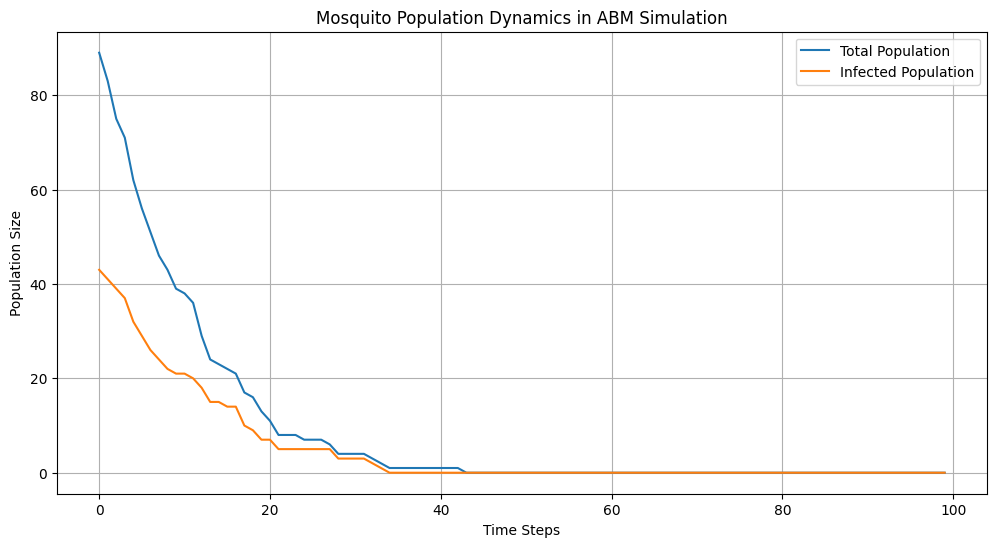

In [ ]:
class Mosquito:
    def __init__(self, infected=False):
        self.age = 0
        self.alive = True
        self.infected = infected  # Whether the mosquito is infected with the symbiont

    def update(self, beta, theta1, total_population):
        # Simple rules for aging and dying
        self.age += 1
        death_chance = 0.01 + 0.05 * (1 - beta)  # Increased death chance if beta is low
        if np.random.rand() < death_chance:
            self.alive = False

        # Reproduction (influenced by theta1 and the total population)
        if self.alive and np.random.rand() < 0.1 * beta:
            # Infected mosquitoes produce infected offspring
            if self.infected and np.random.rand() < theta1:
                return Mosquito(infected=True)
            elif not self.infected and np.random.rand() > theta1:
                # Susceptible mosquitoes produce susceptible offspring
                return Mosquito(infected=False)
        return None

# Updated simulation loop to include theta1, theta2, and beta
def run_simulation(num_steps, num_initial_infected, num_initial_susceptible, beta_values, theta1_values):
    # Initial mosquito population with a mix of infected and susceptible
    mosquito_population = [Mosquito(infected=True) for _ in range(num_initial_infected)] + \
                          [Mosquito(infected=False) for _ in range(num_initial_susceptible)]

    population_size_over_time = []
    infected_over_time = []

    for step in range(num_steps):
        new_mosquitoes = []
        current_infected = sum(1 for m in mosquito_population if m.infected)
        total_population = len(mosquito_population)
        theta1 = theta1_values[step]

        for mosquito in mosquito_population:
            mosquito.update(beta_values[step], theta1, total_population)
            if mosquito.alive:
                new_mosquito = mosquito.update(beta_values[step], theta1, total_population)
                if new_mosquito:
                    new_mosquitoes.append(new_mosquito)

        mosquito_population.extend(new_mosquitoes)
        mosquito_population = [m for m in mosquito_population if m.alive]
        population_size_over_time.append(len(mosquito_population))
        infected_over_time.append(sum(1 for m in mosquito_population if m.infected))

    return population_size_over_time, infected_over_time

# Example data (replace with your real data)
num_initial_infected = 50
num_initial_susceptible = 50
num_steps = 100
beta_values = np.full(num_steps, 0.03)  # Example constant beta value
theta1_values = np.linspace(0.1, 0.9, num_steps)  # Linearly increasing theta1 for demonstration

population_size, infected_population = run_simulation(num_steps, num_initial_infected, num_initial_susceptible, beta_values, theta1_values)

# Plotting the results
plt.figure(figsize=(12, 6))

plt.plot(population_size, label='Total Population')
plt.plot(infected_population, label='Infected Population')

plt.xlabel('Time Steps')
plt.ylabel('Population Size')
plt.title('Mosquito Population Dynamics in ABM Simulation')
plt.legend()
plt.grid(True)
plt.show()


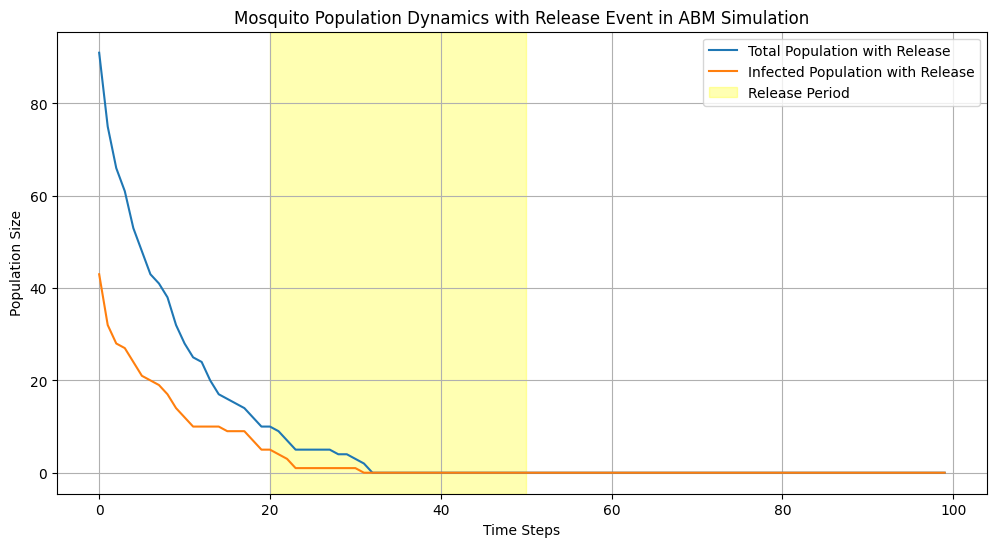

In [ ]:
# Example values for the release event
release_start = 20  # Start the release at time step 20
release_duration = 30  # Release lasts for 30 time steps
theta1_during_release = 0.9  # Elevated theta1 value during the release

# Adjust theta1 values to simulate the release
theta1_values_with_release = np.linspace(0.1, 0.9, num_steps)
theta1_values_with_release[release_start:release_start+release_duration] = theta1_during_release

# Run the simulation with the release event
population_size_with_release, infected_population_with_release = run_simulation(
    num_steps, num_initial_infected, num_initial_susceptible, beta_values, theta1_values_with_release)

# Plotting the results with the release event
plt.figure(figsize=(12, 6))

plt.plot(population_size_with_release, label='Total Population with Release')
plt.plot(infected_population_with_release, label='Infected Population with Release')

plt.axvspan(release_start, release_start+release_duration, color='yellow', alpha=0.3, label='Release Period')

plt.xlabel('Time Steps')
plt.ylabel('Population Size')
plt.title('Mosquito Population Dynamics with Release Event in ABM Simulation')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
def run_simulation_with_output(num_steps, num_initial_infected, num_initial_susceptible, beta_values, theta1_values, release_start, release_duration):
    # Initialize the mosquito population
    mosquito_population = [Mosquito(infected=True) for _ in range(num_initial_infected)] + \
                          [Mosquito(infected=False) for _ in range(num_initial_susceptible)]

    # Data storage for output
    data = {
        "time_step": [],
        "released": [],
        "total_population": [],
        "infected_population": [],
        "non_infected_population": [],
        "prevalence": [],
        "susceptibility": []
    }

    for step in range(num_steps):
        # Determine if we are in the release period and release mosquitoes if we are
        released = 0
        if release_start <= step < release_start + release_duration:
            # Assuming a constant number of mosquitoes are released at each step during the release period
            released = 10  # Example value, can be adjusted
            for _ in range(released):
                mosquito_population.append(Mosquito(infected=True))

        # Update the mosquito population
        new_mosquitoes = []
        total_population = len(mosquito_population)
        theta1 = theta1_values[step]

        for mosquito in mosquito_population:
            mosquito.update(beta_values[step], theta1, total_population)
            if mosquito.alive:
                new_mosquito = mosquito.update(beta_values[step], theta1, total_population)
                if new_mosquito:
                    new_mosquitoes.append(new_mosquito)

        mosquito_population.extend(new_mosquitoes)
        mosquito_population = [m for m in mosquito_population if m.alive]

        # Update data for output
        current_infected = sum(1 for m in mosquito_population if m.infected)
        current_non_infected = total_population - current_infected
        prevalence = current_infected / total_population if total_population > 0 else 0
        susceptibility = 1 - prevalence

        data["time_step"].append(step)
        data["released"].append(released)
        data["total_population"].append(total_population)
        data["infected_population"].append(current_infected)
        data["non_infected_population"].append(current_non_infected)
        data["prevalence"].append(prevalence)
        data["susceptibility"].append(susceptibility)

    return data

# Running the simulation with the release event and collecting the output
simulation_data = run_simulation_with_output(
    num_steps, num_initial_infected, num_initial_susceptible, beta_values, theta1_values_with_release, release_start, release_duration)

# Display the output data
simulation_data_df = pd.DataFrame(simulation_data)
simulation_data_df.head()  # Displaying the first few rows of the dataframe

# Save the DataFrame to an Excel file
excel_filename = "/content/sample_data.ab.xlsx"
simulation_data_df.to_excel(excel_filename, index=False)

In [ ]:
import numpy as np
import pandas as pd

# Seed for reproducibility
np.random.seed(900)

class Mosquito:
    def __init__(self, infected=False):
        self.infected = infected
        self.age = 0
        self.alive = True

    def update(self, params):
        # Update age and determine if the mosquito survives to the next step
        self.age += 1
        death_chance = params['base_death_rate'] + params['age_death_rate'] * self.age
        self.alive = np.random.rand() > death_chance

        # Determine if the mosquito reproduces
        if self.alive and np.random.rand() < params['reproduction_rate']:
            return Mosquito(infected=self.infected)
        return None

class Simulation:
    def __init__(self, initial_infected, initial_susceptible, params):
        self.mosquitoes = [Mosquito(infected=True) for _ in range(initial_infected)] + \
                          [Mosquito(infected=False) for _ in range(initial_susceptible)]
        self.params = params
        self.data = []

    def step(self):
        new_mosquitoes = []
        for mosquito in self.mosquitoes:
            mosquito.update(self.params)
            if mosquito.alive:
                new_offspring = mosquito.update(self.params)
                if new_offspring:
                    new_mosquitoes.append(new_offspring)
        self.mosquitoes.extend(new_mosquitoes)
        self.mosquitoes = [m for m in self.mosquitoes if m.alive]

        # Record data
        infected = sum(m.infected for m in self.mosquitoes)
        total = len(self.mosquitoes)
        self.data.append({
            'total_population': total,
            'infected_population': infected,
            'non_infected_population': total - infected,
            'prevalence': infected / total if total > 0 else 0
        })

    def run(self, num_steps, release_schedule=None):
        for step in range(num_steps):
            # Release infected mosquitoes according to the schedule
            if release_schedule and step in release_schedule:
                for _ in range(release_schedule[step]):
                    self.mosquitoes.append(Mosquito(infected=True))
            self.step()

        return pd.DataFrame(self.data)

# Parameters and initial conditions
params = {
    'base_death_rate': 0.01,
    'age_death_rate': 0.005,
    'reproduction_rate': 0.1
}
initial_infected = 50
initial_susceptible = 50
num_steps = 100
release_schedule = {20: 10, 21: 10, 22: 10}  # Example: release 10 mosquitoes on steps 20, 21, and 22

# Run the simulation
sim = Simulation(initial_infected, initial_susceptible, params)
results = sim.run(num_steps, release_schedule)

# Display results
print(results.head())


   total_population  infected_population  non_infected_population  prevalence
0               109                   54                       55    0.495413
1               105                   51                       54    0.485714
2               110                   51                       59    0.463636
3               109                   50                       59    0.458716
4               107                   48                       59    0.448598


In [ ]:
import numpy as np
import pandas as pd

# Seed for reproducibility
np.random.seed(900)

class Mosquito:
    def __init__(self, infected=False):
        self.infected = infected
        self.age = 0
        self.alive = True

    def update(self, params):
        # Update age and determine if the mosquito survives to the next step
        self.age += 1
        death_chance = params['base_death_rate'] + params['age_death_rate'] * self.age
        self.alive = np.random.rand() > death_chance

        # Determine if the mosquito reproduces
        if self.alive and np.random.rand() < params['reproduction_rate']:
            return Mosquito(infected=self.infected)
        return None

class Simulation:
    def __init__(self, initial_infected, initial_susceptible, params):
        self.mosquitoes = [Mosquito(infected=True) for _ in range(initial_infected)] + \
                          [Mosquito(infected=False) for _ in range(initial_susceptible)]
        self.params = params
        self.data = []

    def step(self):
        new_mosquitoes = []
        for mosquito in self.mosquitoes:
            mosquito.update(self.params)
            if mosquito.alive:
                new_offspring = mosquito.update(self.params)
                if new_offspring:
                    new_mosquitoes.append(new_offspring)
        self.mosquitoes.extend(new_mosquitoes)
        self.mosquitoes = [m for m in self.mosquitoes if m.alive]

        # Record data
        infected = sum(m.infected for m in self.mosquitoes)
        total = len(self.mosquitoes)
        self.data.append({
            'total_population': total,
            'infected_population': infected,
            'non_infected_population': total - infected,
            'prevalence': infected / total if total > 0 else 0
        })

    def run(self, num_steps, release_schedule=None):
        for step in range(num_steps):
            # Release infected mosquitoes according to the schedule
            if release_schedule and step in release_schedule:
                for _ in range(release_schedule[step]):
                    self.mosquitoes.append(Mosquito(infected=True))
            self.step()

        return pd.DataFrame(self.data)

# Parameters and initial conditions
params = {
    'base_death_rate': 0.01,
    'age_death_rate': 0.005,
    'reproduction_rate': 0.1
}
initial_infected = 50
initial_susceptible = 50
num_steps = 100
release_schedule = {20: 10, 21: 10, 22: 10}  # Example: release 10 mosquitoes on steps 20, 21, and 22

# Run the simulation
sim = Simulation(initial_infected, initial_susceptible, params)
results = sim.run(num_steps, release_schedule)

# Display results
print(results.head())


   total_population  infected_population  non_infected_population  prevalence
0               109                   54                       55    0.495413
1               105                   51                       54    0.485714
2               110                   51                       59    0.463636
3               109                   50                       59    0.458716
4               107                   48                       59    0.448598


In [ ]:
import numpy as np
import pandas as pd

# Seed for reproducibility
np.random.seed(900)

class Mosquito:
    def __init__(self, infected=False):
        self.infected = infected
        self.age = 0
        self.alive = True

    def update(self, params):
        # Update age and determine if the mosquito survives to the next step
        self.age += 1
        death_chance = params['base_death_rate'] + params['age_death_rate'] * self.age
        self.alive = np.random.rand() > death_chance

        # Determine if the mosquito reproduces
        if self.alive and np.random.rand() < params['reproduction_rate']:
            return Mosquito(infected=self.infected)
        return None

class Simulation:
    def __init__(self, initial_infected, initial_susceptible, params):
        self.mosquitoes = [Mosquito(infected=True) for _ in range(initial_infected)] + \
                          [Mosquito(infected=False) for _ in range(initial_susceptible)]
        self.params = params
        self.data = []

    def step(self, released=0):
        new_mosquitoes = []
        for mosquito in self.mosquitoes:
            mosquito.update(self.params)
            if mosquito.alive:
                new_offspring = mosquito.update(self.params)
                if new_offspring:
                    new_mosquitoes.append(new_offspring)
        self.mosquitoes.extend(new_mosquitoes)
        self.mosquitoes = [m for m in self.mosquitoes if m.alive]

        # Record data
        infected = sum(m.infected for m in self.mosquitoes)
        total = len(self.mosquitoes)
        self.data.append({
            'released': released,
            'total_population': total,
            'infected_population': infected,
            'non_infected_population': total - infected,
            'prevalence': infected / total if total > 0 else 0
        })

    def run(self, num_steps, release_schedule=None):
        for step in range(num_steps):
            released = 0
            # Release infected mosquitoes according to the schedule
            if release_schedule and step in release_schedule:
                released = release_schedule[step]
                for _ in range(released):
                    self.mosquitoes.append(Mosquito(infected=True))
            self.step(released)

        return pd.DataFrame(self.data)

# Parameters and initial conditions
params = {
    'base_death_rate': 0.01,
    'age_death_rate': 0.005,
    'reproduction_rate': 0.1
}
initial_infected = 50
initial_susceptible = 50
num_steps = 100
release_schedule = {20: 10, 21: 10, 22: 10}  # Example: release 10 mosquitoes on steps 20, 21, and 22

# Run the simulation
sim = Simulation(initial_infected, initial_susceptible, params)
results = sim.run(num_steps, release_schedule)

# Display results
print(results.head(25))


    released  total_population  infected_population  non_infected_population  \
0          0               109                   54                       55   
1          0               105                   51                       54   
2          0               110                   51                       59   
3          0               109                   50                       59   
4          0               107                   48                       59   
5          0                96                   45                       51   
6          0                84                   40                       44   
7          0                81                   39                       42   
8          0                79                   37                       42   
9          0                75                   36                       39   
10         0                70                   34                       36   
11         0                74          

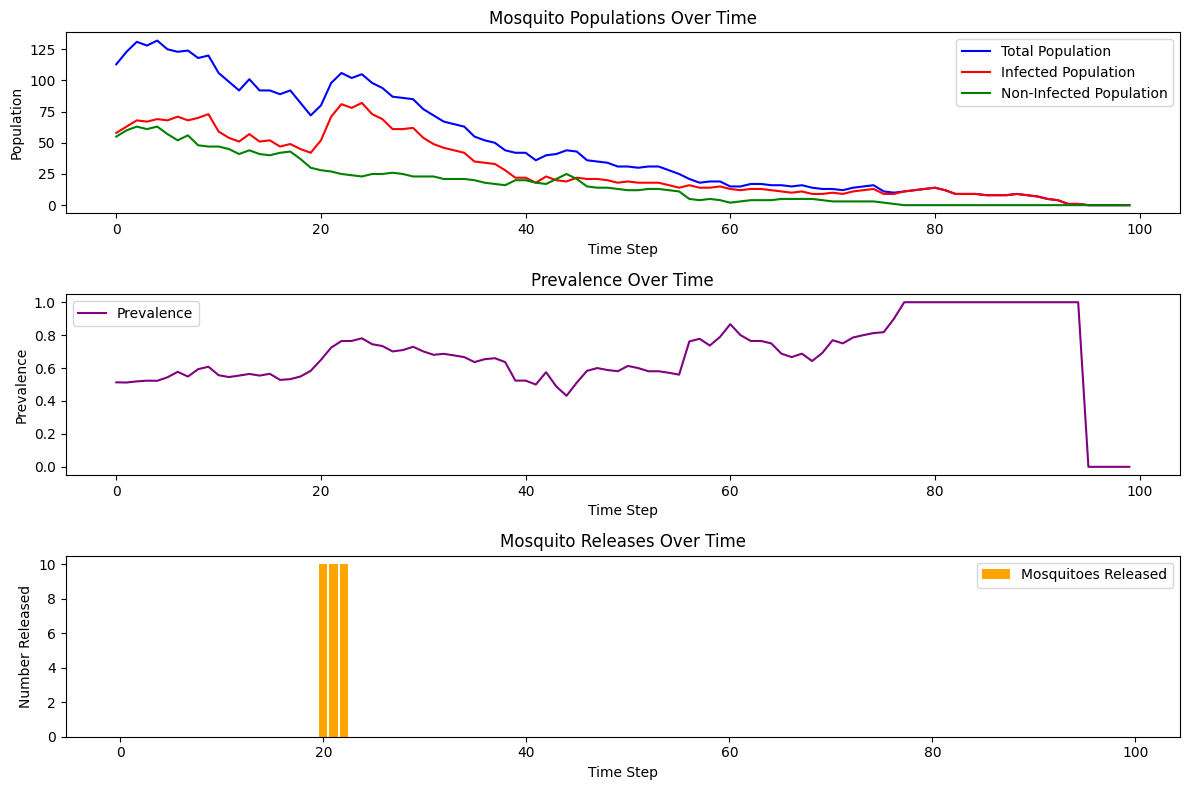

In [ ]:
import matplotlib.pyplot as plt

# Running the simulation and storing the results
sim = Simulation(initial_infected, initial_susceptible, params)
results = sim.run(num_steps, release_schedule)

# Plotting the results
plt.figure(figsize=(12, 8))

# Plot for total, infected, and non-infected mosquito populations
plt.subplot(3, 1, 1)
plt.plot(results['total_population'], label='Total Population', color='blue')
plt.plot(results['infected_population'], label='Infected Population', color='red')
plt.plot(results['non_infected_population'], label='Non-Infected Population', color='green')
plt.title('Mosquito Populations Over Time')
plt.xlabel('Time Step')
plt.ylabel('Population')
plt.legend()

# Plot for prevalence
plt.subplot(3, 1, 2)
plt.plot(results['prevalence'], label='Prevalence', color='purple')
plt.title('Prevalence Over Time')
plt.xlabel('Time Step')
plt.ylabel('Prevalence')
plt.legend()

# Plot for number of mosquitoes released
plt.subplot(3, 1, 3)
plt.bar(range(len(results)), results['released'], label='Mosquitoes Released', color='orange')
plt.title('Mosquito Releases Over Time')
plt.xlabel('Time Step')
plt.ylabel('Number Released')
plt.legend()

plt.tight_layout()
plt.show()



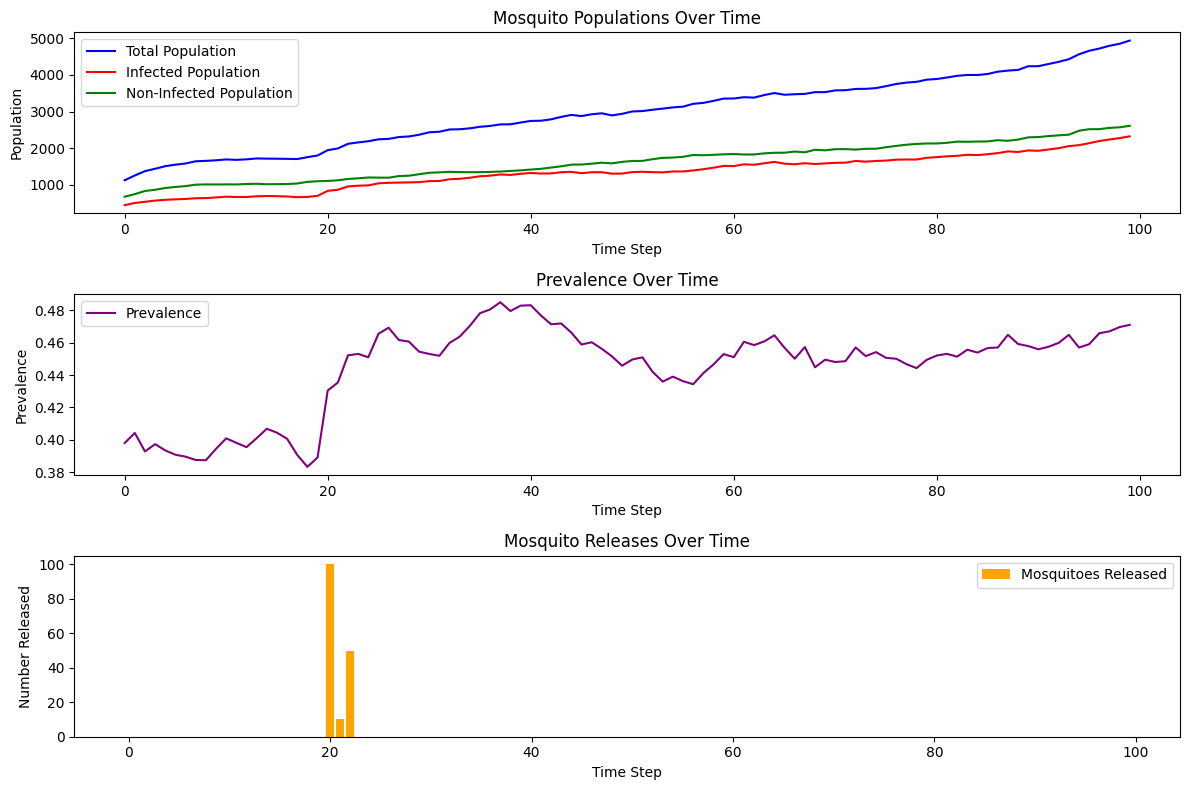

In [ ]:
# Re-defining the classes and running the simulation again

class Mosquito:
    def __init__(self, infected=False):
        self.infected = infected
        self.age = 0
        self.alive = True

    def update(self, params):
        self.age += 1
        death_chance = params['base_death_rate'] + params['age_death_rate'] * self.age
        self.alive = np.random.rand() > death_chance

        if self.alive and np.random.rand() < params['reproduction_rate']:
            return Mosquito(infected=self.infected)
        return None

class Simulation:
    def __init__(self, initial_infected, initial_susceptible, params):
        self.mosquitoes = [Mosquito(infected=True) for _ in range(initial_infected)] + \
                          [Mosquito(infected=False) for _ in range(initial_susceptible)]
        self.params = params
        self.data = []

    def step(self, released=0):
        new_mosquitoes = []
        for mosquito in self.mosquitoes:
            mosquito.update(self.params)
            if mosquito.alive:
                new_offspring = mosquito.update(self.params)
                if new_offspring:
                    new_mosquitoes.append(new_offspring)
        self.mosquitoes.extend(new_mosquitoes)
        self.mosquitoes = [m for m in self.mosquitoes if m.alive]

        infected = sum(m.infected for m in self.mosquitoes)
        total = len(self.mosquitoes)
        self.data.append({
            'released': released,
            'total_population': total,
            'infected_population': infected,
            'non_infected_population': total - infected,
            'prevalence': infected / total if total > 0 else 0
        })

    def run(self, num_steps, release_schedule=None):
        for step in range(num_steps):
            released = 0
            if release_schedule and step in release_schedule:
                released = release_schedule[step]
                for _ in range(released):
                    self.mosquitoes.append(Mosquito(infected=True))
            self.step(released)

        return pd.DataFrame(self.data)

# Parameters and initial conditions
params = {
    'base_death_rate': 0.01,
    'age_death_rate': 0.005,
    'reproduction_rate': 0.15
}
initial_infected = 400
initial_susceptible = 600
num_steps = 100
release_schedule = {20: 100, 21: 10, 22: 50}  # Example: release 10 mosquitoes on steps 20, 21, and 22

# Running the simulation
sim = Simulation(initial_infected, initial_susceptible, params)
results = sim.run(num_steps, release_schedule)

# Plotting
plt.figure(figsize=(12, 8))

plt.subplot(3, 1, 1)
plt.plot(results['total_population'], label='Total Population', color='blue')
plt.plot(results['infected_population'], label='Infected Population', color='red')
plt.plot(results['non_infected_population'], label='Non-Infected Population', color='green')
plt.title('Mosquito Populations Over Time')
plt.xlabel('Time Step')
plt.ylabel('Population')
plt.legend()

plt.subplot(3, 1, 2)
plt.plot(results['prevalence'], label='Prevalence', color='purple')
plt.title('Prevalence Over Time')
plt.xlabel('Time Step')
plt.ylabel('Prevalence')
plt.legend()

plt.subplot(3, 1, 3)
plt.bar(range(len(results)), results['released'], label='Mosquitoes Released', color='orange')
plt.title('Mosquito Releases Over Time')
plt.xlabel('Time Step')
plt.ylabel('Number Released')
plt.legend()

plt.tight_layout()
plt.show()



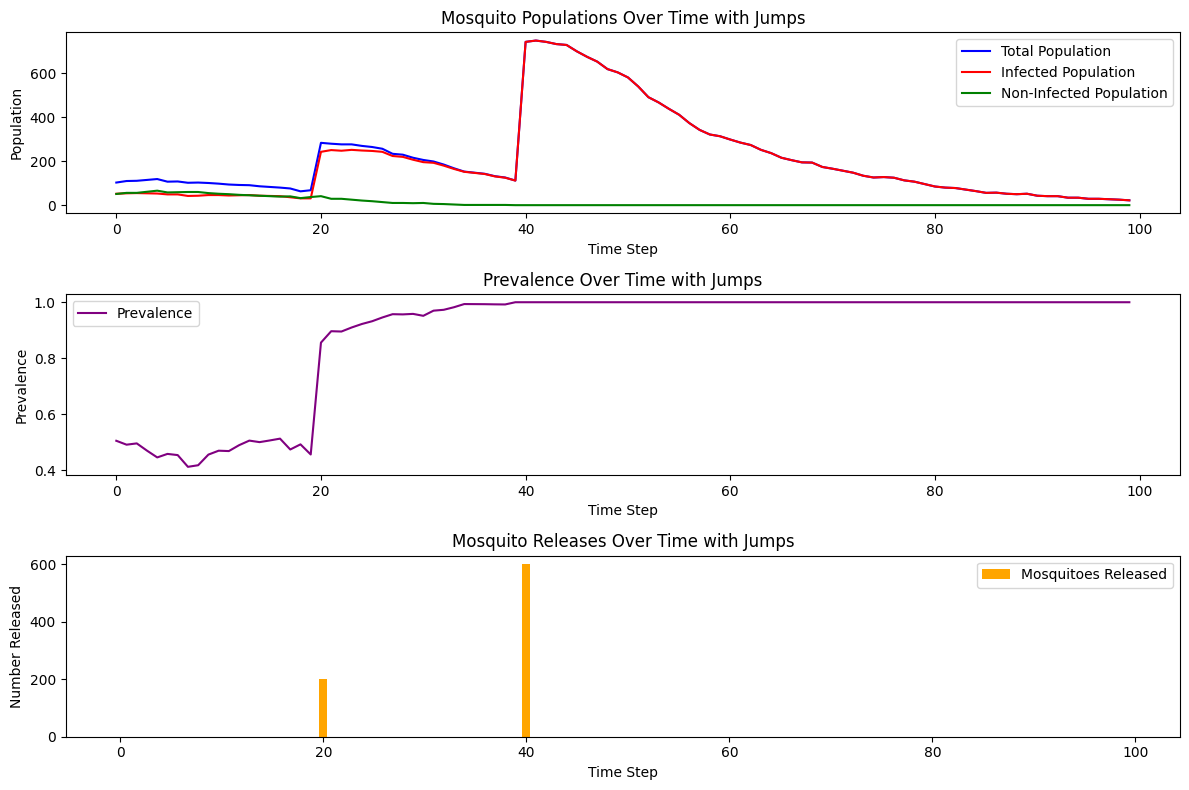

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Re-defining the Mosquito and Simulation classes

class Mosquito:
    def __init__(self, infected=False):
        self.infected = infected
        self.age = 0
        self.alive = True

    def update(self, params):
        self.age += 1
        death_chance = params['base_death_rate'] + params['age_death_rate'] * self.age
        self.alive = np.random.rand() > death_chance

        if self.alive and np.random.rand() < params['reproduction_rate']:
            return Mosquito(infected=self.infected)
        return None

class Simulation:
    def __init__(self, initial_infected, initial_susceptible, params):
        self.mosquitoes = [Mosquito(infected=True) for _ in range(initial_infected)] + \
                          [Mosquito(infected=False) for _ in range(initial_susceptible)]
        self.params = params
        self.data = []

    def step(self, released=0):
        new_mosquitoes = []
        for mosquito in self.mosquitoes:
            mosquito.update(self.params)
            if mosquito.alive:
                new_offspring = mosquito.update(self.params)
                if new_offspring:
                    new_mosquitoes.append(new_offspring)
        self.mosquitoes.extend(new_mosquitoes)
        self.mosquitoes = [m for m in self.mosquitoes if m.alive]

        infected = sum(m.infected for m in self.mosquitoes)
        total = len(self.mosquitoes)
        self.data.append({
            'released': released,
            'total_population': total,
            'infected_population': infected,
            'non_infected_population': total - infected,
            'prevalence': infected / total if total > 0 else 0
        })

    def run(self, num_steps, release_schedule=None):
        for step in range(num_steps):
            released = 0
            if release_schedule and step in release_schedule:
                released = release_schedule[step]
                for _ in range(released):
                    self.mosquitoes.append(Mosquito(infected=True))
            self.step(released)

        return pd.DataFrame(self.data)

# Parameters and initial conditions
params = {
    'base_death_rate': 0.01,
    'age_death_rate': 0.005,
    'reproduction_rate': 0.1
}
initial_infected = 50
initial_susceptible = 50
num_steps = 100
release_schedule_with_jumps = {20: 200, 40: 600, 60: 0}  # Large releases at steps 20, 40, and 60
#release_schedule_with_jumps = {20: 500, 40: 1000, 60: 800}  # Large releases at steps 20, 40, and 60
# Running the simulation with the adjusted release schedule
sim_with_jumps = Simulation(initial_infected, initial_susceptible, params)
results_with_jumps = sim_with_jumps.run(num_steps, release_schedule_with_jumps)

# Plotting with the new results
plt.figure(figsize=(12, 8))

plt.subplot(3, 1, 1)
plt.plot(results_with_jumps['total_population'], label='Total Population', color='blue')
plt.plot(results_with_jumps['infected_population'], label='Infected Population', color='red')
plt.plot(results_with_jumps['non_infected_population'], label='Non-Infected Population', color='green')
plt.title('Mosquito Populations Over Time with Jumps')
plt.xlabel('Time Step')
plt.ylabel('Population')
plt.legend()

plt.subplot(3, 1, 2)
plt.plot(results_with_jumps['prevalence'], label='Prevalence', color='purple')
plt.title('Prevalence Over Time with Jumps')
plt.xlabel('Time Step')
plt.ylabel('Prevalence')
plt.legend()

plt.subplot(3, 1, 3)
plt.bar(range(len(results_with_jumps)), results_with_jumps['released'], label='Mosquitoes Released', color='orange')
plt.title('Mosquito Releases Over Time with Jumps')
plt.xlabel('Time Step')
plt.ylabel('Number Released')
plt.legend()

plt.tight_layout()
plt.show()



In [ ]:
# Updating the mosquito population model to include eggs and larvae, both infected and uninfected

class Egg:
    def __init__(self, infected):
        self.infected = infected
        self.age = 0

    def develop(self, params):
        self.age += 1
        if self.age >= params['egg_development_time']:
            return Larva(infected=self.infected)
        return None

class Larva:
    def __init__(self, infected):
        self.infected = infected
        self.age = 0

    def develop(self, params):
        self.age += 1
        if self.infected and self.age >= params['infected_larva_development_time']:
            return Mosquito(infected=True)
        elif not self.infected and self.age >= params['uninfected_larva_development_time']:
            return Mosquito(infected=False)
        return None

class Mosquito:
    def __init__(self, infected=False):
        self.infected = infected
        self.age = 0
        self.alive = True

    def update(self, params):
        self.age += 1
        death_chance = params['base_death_rate'] + params['age_death_rate'] * self.age
        self.alive = np.random.rand() > death_chance

        if self.alive and np.random.rand() < params['reproduction_rate']:
            is_infected_egg = self.infected and np.random.rand() < params['infection_rate_in_eggs']
            return Egg(infected=is_infected_egg)
        return None

class Simulation:
    def __init__(self, initial_infected, initial_susceptible, params):
        self.mosquitoes = [Mosquito(infected=True) for _ in range(initial_infected)] + \
                          [Mosquito(infected=False) for _ in range(initial_susceptible)]
        self.eggs = []
        self.larvae = []
        self.params = params
        self.data = []

    def step(self, released=0):
        # Update mosquitoes and generate eggs
        new_eggs = []
        for mosquito in self.mosquitoes:
            mosquito.update(self.params)
            if mosquito.alive:
                new_egg = mosquito.update(self.params)
                if new_egg:
                    new_eggs.append(new_egg)
        self.eggs.extend(new_eggs)
        self.mosquitoes = [m for m in self.mosquitoes if m.alive]

        # Develop eggs into larvae
        new_larvae = []
        for egg in self.eggs:
            new_larva = egg.develop(self.params)
            if new_larva:
                new_larvae.append(new_larva)
        self.larvae.extend(new_larvae)
        self.eggs = [e for e in self.eggs if e.age < self.params['egg_development_time']]

        # Develop larvae into mosquitoes
        new_mosquitoes = []
        for larva in self.larvae:
            new_mosquito = larva.develop(self.params)
            if new_mosquito:
                new_mosquitoes.append(new_mosquito)
        self.mosquitoes.extend(new_mosquitoes)
        self.larvae = [l for l in self.larvae if l.age < self.params['infected_larva_development_time'] and not l.infected or
                                                   l.age < self.params['uninfected_larva_development_time'] and l.infected]

        # Record data
        infected = sum(m.infected for m in self.mosquitoes)
        total = len(self.mosquitoes)
        total_eggs = len(self.eggs)
        total_larvae = len(self.larvae)
        infected_eggs = sum(e.infected for e in self.eggs)
        infected_larvae = sum(l.infected for l in self.larvae)
        self.data.append({
            'released': released,
            'total_population': total,
            'infected_population': infected,
            'non_infected_population': total - infected,
            'prevalence': infected / total if total > 0 else 0,
            'total_eggs': total_eggs,
            'total_larvae': total_larvae,
            'infected_eggs': infected_eggs,
            'infected_larvae': infected_larvae
        })

    def run(self, num_steps, release_schedule=None):
        for step in range(num_steps):
            released = 0
            if release_schedule and step in release_schedule:
                released = release_schedule[step]
                for _ in range(released):
                    self.mosquitoes.append(Mosquito(infected=True))
            self.step(released)

        return pd.DataFrame(self.data)




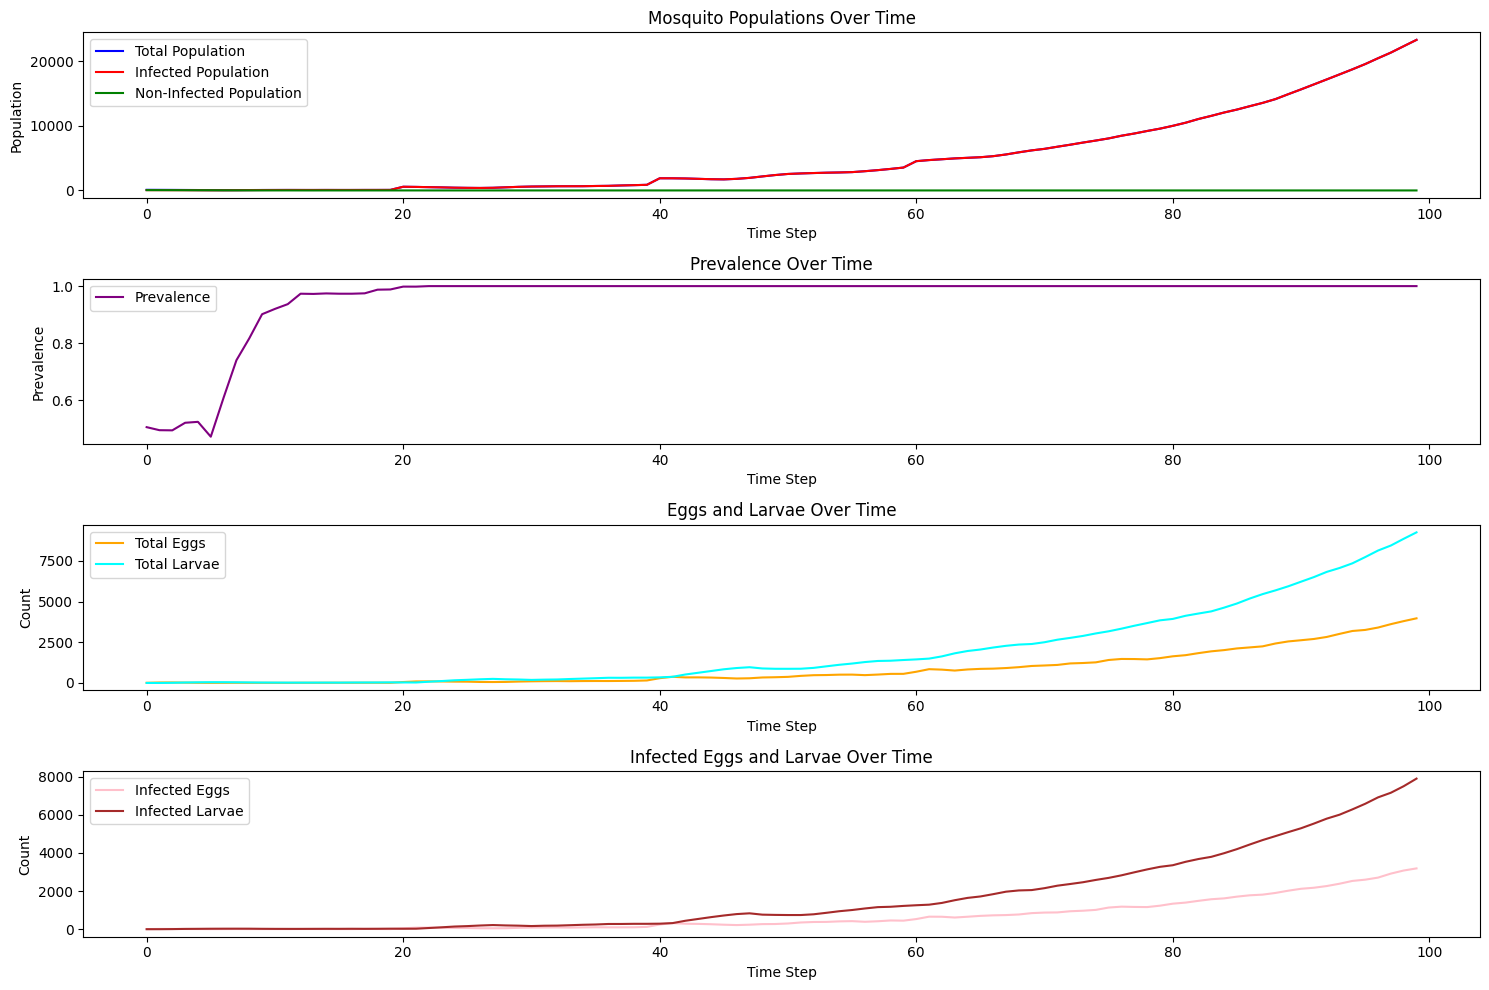

In [ ]:
# Setting parameters and initial conditions for the simulation with the updated model
params = {
    'base_death_rate': 0.01,
    'age_death_rate': 0.005,
    'reproduction_rate': 0.1,
    'infection_rate_in_eggs': 0.8,  # 80% chance of eggs from infected mosquitoes being infected
    'egg_development_time': 3,  # Time for an egg to develop into a larva
    'infected_larva_development_time': 5,  # Time for an infected larva to develop into an adult
    'uninfected_larva_development_time': 7  # Time for an uninfected larva to develop into an adult
}
initial_infected = 50
initial_susceptible = 50
num_steps = 100
release_schedule = {20: 500, 40: 1000, 60: 800}  # Large releases at steps 20, 40, and 60

# Running the simulation
sim = Simulation(initial_infected, initial_susceptible, params)
results = sim.run(num_steps, release_schedule)

# Plotting the results
plt.figure(figsize=(15, 10))

# Plotting total, infected, and non-infected mosquito populations
plt.subplot(4, 1, 1)
plt.plot(results['total_population'], label='Total Population', color='blue')
plt.plot(results['infected_population'], label='Infected Population', color='red')
plt.plot(results['non_infected_population'], label='Non-Infected Population', color='green')
plt.title('Mosquito Populations Over Time')
plt.xlabel('Time Step')
plt.ylabel('Population')
plt.legend()

# Plotting prevalence
plt.subplot(4, 1, 2)
plt.plot(results['prevalence'], label='Prevalence', color='purple')
plt.title('Prevalence Over Time')
plt.xlabel('Time Step')
plt.ylabel('Prevalence')
plt.legend()

# Plotting total eggs and larvae
plt.subplot(4, 1, 3)
plt.plot(results['total_eggs'], label='Total Eggs', color='orange')
plt.plot(results['total_larvae'], label='Total Larvae', color='cyan')
plt.title('Eggs and Larvae Over Time')
plt.xlabel('Time Step')
plt.ylabel('Count')
plt.legend()

# Plotting infected eggs and larvae
plt.subplot(4, 1, 4)
plt.plot(results['infected_eggs'], label='Infected Eggs', color='pink')
plt.plot(results['infected_larvae'], label='Infected Larvae', color='brown')
plt.title('Infected Eggs and Larvae Over Time')
plt.xlabel('Time Step')
plt.ylabel('Count')
plt.legend()

plt.tight_layout()
plt.show()



In [ ]:
# Full code for the updated mosquito population model including eggs, larvae, and pupae

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

class Egg:
    def __init__(self, infected):
        self.infected = infected
        self.age = 0

    def develop(self, params):
        self.age += 1
        if self.age >= params['egg_development_time']:
            return Larva(infected=self.infected)
        return None

class Larva:
    def __init__(self, infected):
        self.infected = infected
        self.age = 0

    def develop(self, params):
        self.age += 1
        if self.age >= params['larva_development_time']:
            return Pupa(infected=self.infected)
        return None

class Pupa:
    def __init__(self, infected):
        self.infected = infected
        self.age = 0

    def develop(self, params):
        self.age += 1
        if self.infected and self.age >= params['infected_pupa_development_time']:
            return Mosquito(infected=True)
        elif not self.infected and self.age >= params['uninfected_pupa_development_time']:
            return Mosquito(infected=False)
        return None

class Mosquito:
    def __init__(self, infected=False):
        self.infected = infected
        self.age = 0
        self.alive = True

    def update(self, params):
        self.age += 1
        death_chance = params['base_death_rate'] + params['age_death_rate'] * self.age
        self.alive = np.random.rand() > death_chance

        if self.alive and np.random.rand() < params['reproduction_rate']:
            is_infected_egg = self.infected and np.random.rand() < params['infection_rate_in_eggs']
            return Egg(infected=is_infected_egg)
        return None

class Simulation:
    def __init__(self, initial_infected, initial_susceptible, params):
        self.mosquitoes = [Mosquito(infected=True) for _ in range(initial_infected)] + \
                          [Mosquito(infected=False) for _ in range(initial_susceptible)]
        self.eggs = []
        self.larvae = []
        self.pupae = []
        self.params = params
        self.data = []

    def step(self, released=0):
        new_eggs = []
        for mosquito in self.mosquitoes:
            mosquito.update(self.params)
            if mosquito.alive:
                new_egg = mosquito.update(self.params)
                if new_egg:
                    new_eggs.append(new_egg)
        self.eggs.extend(new_eggs)
        self.mosquitoes = [m for m in self.mosquitoes if m.alive]

        new_larvae = []
        for egg in self.eggs:
            new_larva = egg.develop(self.params)
            if new_larva:
                new_larvae.append(new_larva)
        self.larvae.extend(new_larvae)
        self.eggs = [e for e in self.eggs if e.age < self.params['egg_development_time']]

        new_pupae = []
        for larva in self.larvae:
            new_pupa = larva.develop(self.params)
            if new_pupa:
                new_pupae.append(new_pupa)
        self.pupae.extend(new_pupae)
        self.larvae = [l for l in self.larvae if l.age < self.params['larva_development_time']]

        new_mosquitoes = []
        for pupa in self.pupae:
            new_mosquito = pupa.develop(self.params)
            if new_mosquito:
                new_mosquitoes.append(new_mosquito)
        self.mosquitoes.extend(new_mosquitoes)
        self.pupae = [p for p in self.pupae if (p.infected and p.age < self.params['infected_pupa_development_time']) or
                                                  (not p.infected and p.age < self.params['uninfected_pupa_development_time'])]

        infected = sum(m.infected for m in self.mosquitoes)
        total = len(self.mosquitoes)
        total_eggs = len(self.eggs)
        total_larvae = len(self.larvae)
        total_pupae = len(self.pupae)
        infected_eggs = sum(e.infected for e in self.eggs)
        infected_larvae = sum(l.infected for l in self.larvae)
        infected_pupae = sum(p.infected for p in self.pupae)
        self.data.append({
            'total_population': total,
            'infected_population': infected,
            'non_infected_population': total - infected,
            'prevalence': infected / total if total > 0 else 0,
            'total_eggs': total_eggs,
            'total_larvae': total_larvae,
            'total_pupae': total_pupae,
            'infected_eggs': infected_eggs,
            'infected_larvae': infected_larvae,
            'infected_pupae': infected_pupae
        })

        # Release additional mosquitoes
        if released > 0:
            self.mosquitoes.extend([Mosquito(infected=True) for _ in range(released)])

    def run(self, steps, release_schedule):
        for step in range(steps):
            self.step(released=release_schedule.get(step, 0))
        return pd.DataFrame(self.data)

# Parameters for the simulation
params = {
    'base_death_rate': 0.01,
    'age_death_rate': 0.005,
    'reproduction_rate': 0.1,
    'infection_rate_in_eggs': 0.8,
    'egg_development_time': 3,
    'larva_development_time': 4,
    'infected_pupa_development_time': 2,
    'uninfected_pupa_development_time': 3
}

# Running the simulation
initial_infected = 50
initial_susceptible = 50
num_steps = 100
release_schedule = {20: 500, 40: 1000, 60: 800}  # Large releases at steps 20, 40, and 60

sim = Simulation(initial_infected, initial_susceptible, params)
results = sim.run(num_steps, release_schedule)

# Plotting the results
# The plotting code would be similar to what was provided previously, but including the new data on pupae




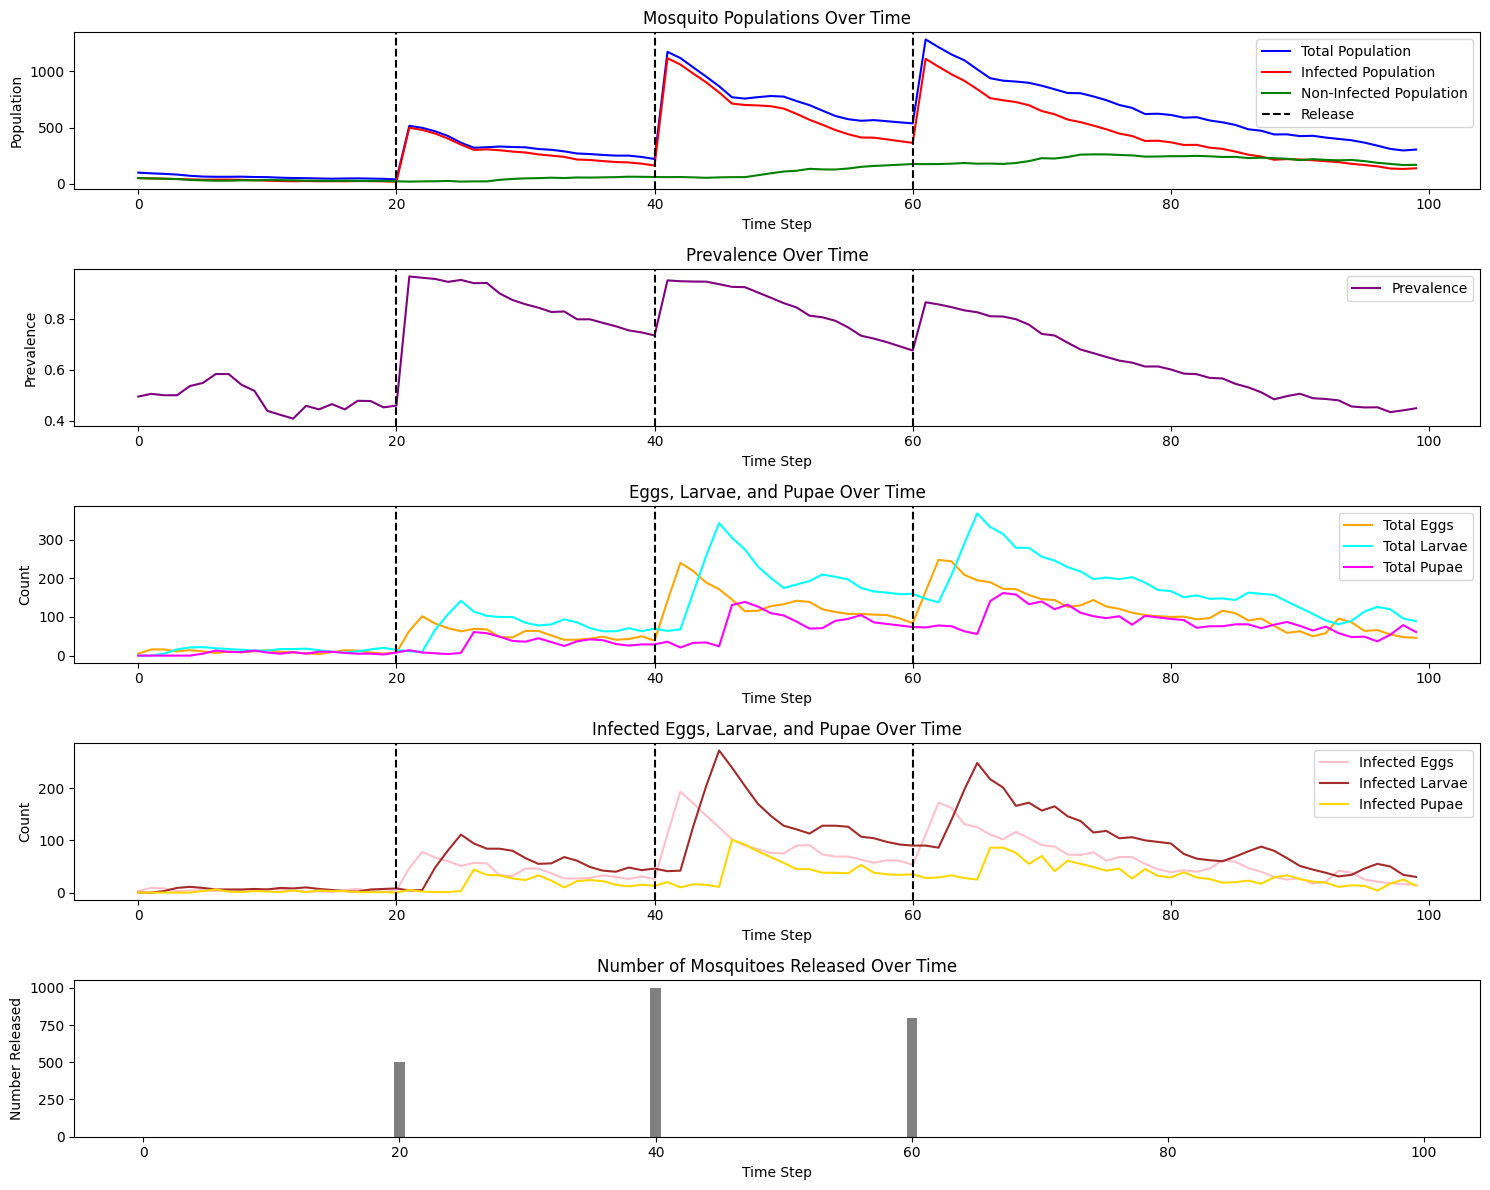

In [ ]:
# Plotting the results including the new data on pupae and highlighting the release events

plt.figure(figsize=(15, 12))

# Plotting total, infected, and non-infected mosquito populations
plt.subplot(5, 1, 1)
plt.plot(results['total_population'], label='Total Population', color='blue')
plt.plot(results['infected_population'], label='Infected Population', color='red')
plt.plot(results['non_infected_population'], label='Non-Infected Population', color='green')
for release_time in release_schedule.keys():
    plt.axvline(x=release_time, color='black', linestyle='--', label='Release' if release_time == 20 else '')
plt.title('Mosquito Populations Over Time')
plt.xlabel('Time Step')
plt.ylabel('Population')
plt.legend()

# Plotting prevalence
plt.subplot(5, 1, 2)
plt.plot(results['prevalence'], label='Prevalence', color='purple')
for release_time in release_schedule.keys():
    plt.axvline(x=release_time, color='black', linestyle='--')
plt.title('Prevalence Over Time')
plt.xlabel('Time Step')
plt.ylabel('Prevalence')
plt.legend()

# Plotting total eggs, larvae, and pupae
plt.subplot(5, 1, 3)
plt.plot(results['total_eggs'], label='Total Eggs', color='orange')
plt.plot(results['total_larvae'], label='Total Larvae', color='cyan')
plt.plot(results['total_pupae'], label='Total Pupae', color='magenta')
for release_time in release_schedule.keys():
    plt.axvline(x=release_time, color='black', linestyle='--')
plt.title('Eggs, Larvae, and Pupae Over Time')
plt.xlabel('Time Step')
plt.ylabel('Count')
plt.legend()

# Plotting infected eggs, larvae, and pupae
plt.subplot(5, 1, 4)
plt.plot(results['infected_eggs'], label='Infected Eggs', color='pink')
plt.plot(results['infected_larvae'], label='Infected Larvae', color='brown')
plt.plot(results['infected_pupae'], label='Infected Pupae', color='gold')
for release_time in release_schedule.keys():
    plt.axvline(x=release_time, color='black', linestyle='--')
plt.title('Infected Eggs, Larvae, and Pupae Over Time')
plt.xlabel('Time Step')
plt.ylabel('Count')
plt.legend()

# Plotting the number of mosquitoes released over time
plt.subplot(5, 1, 5)
released_population = [release_schedule.get(t, 0) for t in range(num_steps)]
plt.bar(range(num_steps), released_population, color='grey')
plt.title('Number of Mosquitoes Released Over Time')
plt.xlabel('Time Step')
plt.ylabel('Number Released')

plt.tight_layout()
plt.show()



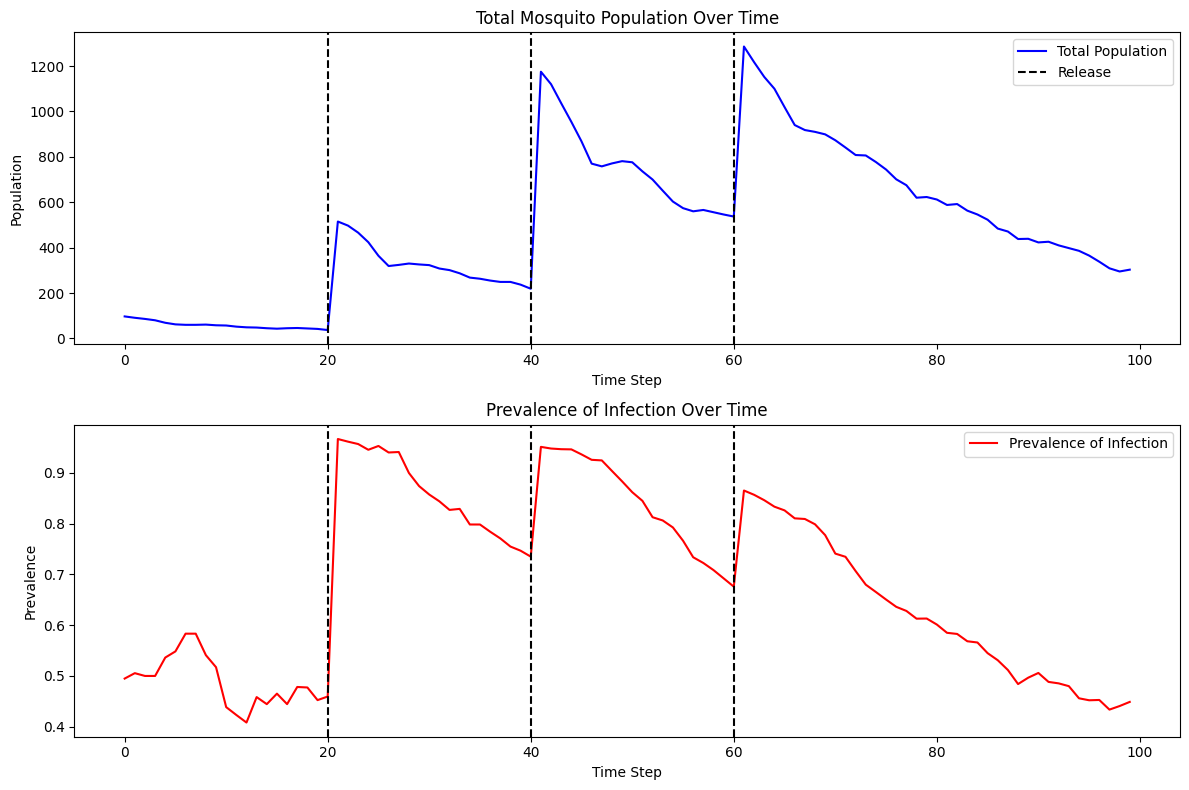

In [ ]:
plt.figure(figsize=(12, 8))

# Plotting total population and highlighting release events
plt.subplot(2, 1, 1)
plt.plot(results['total_population'], label='Total Population', color='blue')
for release_time in release_schedule.keys():
    plt.axvline(x=release_time, color='black', linestyle='--', label='Release' if release_time == 20 else '')
plt.title('Total Mosquito Population Over Time')
plt.xlabel('Time Step')
plt.ylabel('Population')
plt.legend()

# Plotting prevalence of infection
plt.subplot(2, 1, 2)
plt.plot(results['prevalence'], label='Prevalence of Infection', color='red')
for release_time in release_schedule.keys():
    plt.axvline(x=release_time, color='black', linestyle='--')
plt.title('Prevalence of Infection Over Time')
plt.xlabel('Time Step')
plt.ylabel('Prevalence')
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:
# Full code for the updated mosquito population model including eggs, larvae, and pupae

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

class Egg:
    def __init__(self, infected):
        self.infected = infected
        self.age = 0

    def develop(self, params):
        self.age += 1
        if self.age >= params['egg_development_time']:
            return Larva(infected=self.infected)
        return None

class Larva:
    def __init__(self, infected):
        self.infected = infected
        self.age = 0

    def develop(self, params):
        self.age += 1
        if self.age >= params['larva_development_time']:
            return Pupa(infected=self.infected)
        return None

class Pupa:
    def __init__(self, infected):
        self.infected = infected
        self.age = 0

    def develop(self, params):
        self.age += 1
        if self.infected and self.age >= params['infected_pupa_development_time']:
            return Mosquito(infected=True)
        elif not self.infected and self.age >= params['uninfected_pupa_development_time']:
            return Mosquito(infected=False)
        return None

class Mosquito:
    def __init__(self, infected=False):
        self.infected = infected
        self.age = 0
        self.alive = True

    def update(self, params):
        self.age += 1
        death_chance = params['base_death_rate'] + params['age_death_rate'] * self.age
        self.alive = np.random.rand() > death_chance

        if self.alive and np.random.rand() < params['reproduction_rate']:
            is_infected_egg = self.infected and np.random.rand() < params['infection_rate_in_eggs']
            return Egg(infected=is_infected_egg)
        return None

# Correcting the Simulation class by adding the run method

class Simulation:
    def __init__(self, initial_infected, initial_susceptible, params):
        self.mosquitoes = [Mosquito(infected=True) for _ in range(initial_infected)] + \
                          [Mosquito(infected=False) for _ in range(initial_susceptible)]
        self.eggs = []
        self.larvae = []
        self.pupae = []
        self.params = params
        self.data = []

    def step(self, current_step, released=0):
        # Adjust parameters based on seasonality
        self.adjust_for_season(current_step)

        new_eggs = []
        for mosquito in self.mosquitoes:
            mosquito.update(self.params)
            if mosquito.alive:
                new_egg = mosquito.update(self.params)
                if new_egg:
                    new_eggs.append(new_egg)
        self.eggs.extend(new_eggs)
        self.mosquitoes = [m for m in self.mosquitoes if m.alive]

        new_larvae = []
        for egg in self.eggs:
            new_larva = egg.develop(self.params)
            if new_larva:
                new_larvae.append(new_larva)
        self.larvae.extend(new_larvae)
        self.eggs = [e for e in self.eggs if e.age < self.params['egg_development_time']]

        new_pupae = []
        for larva in self.larvae:
            new_pupa = larva.develop(self.params)
            if new_pupa:
                new_pupae.append(new_pupa)
        self.pupae.extend(new_pupae)
        self.larvae = [l for l in self.larvae if l.age < self.params['larva_development_time']]

        new_mosquitoes = []
        for pupa in self.pupae:
            new_mosquito = pupa.develop(self.params)
            if new_mosquito:
                new_mosquitoes.append(new_mosquito)
        self.mosquitoes.extend(new_mosquitoes)
        self.pupae = [p for p in self.pupae if (p.infected and p.age < self.params['infected_pupa_development_time']) or
                                                  (not p.infected and p.age < self.params['uninfected_pupa_development_time'])]

        infected = sum(m.infected for m in self.mosquitoes)
        total = len(self.mosquitoes)
        total_eggs = len(self.eggs)
        total_larvae = len(self.larvae)
        total_pupae = len(self.pupae)
        infected_eggs = sum(e.infected for e in self.eggs)
        infected_larvae = sum(l.infected for l in self.larvae)
        infected_pupae = sum(p.infected for p in self.pupae)

        self.data.append({
            'total_population': total,
            'infected_population': infected,
            'non_infected_population': total - infected,
            'prevalence': infected / total if total > 0 else 0,
            'total_eggs': total_eggs,
            'total_larvae': total_larvae,
            'total_pupae': total_pupae,
            'infected_eggs': infected_eggs,
            'infected_larvae': infected_larvae,
            'infected_pupae': infected_pupae
        })

        # Release additional mosquitoes if scheduled
        if released > 0:
            self.mosquitoes.extend([Mosquito(infected=True) for _ in range(released)])

    def adjust_for_season(self, current_step):
        seasonal_factor = np.sin(2 * np.pi * current_step / self.params['season_length'])
        self.params['birth_rate'] = self.params['base_birth_rate'] * (1 + seasonal_factor)
        self.params['death_rate'] = self.params['base_death_rate'] * (1 - seasonal_factor)

    def run(self, steps, release_schedule):
        for step in range(steps):
            self.step(step, released=release_schedule.get(step, 0))
        return pd.DataFrame(self.data)

# Re-running the simulation
# Parameters for the simulation
params = {
    'base_death_rate': 0.01,
    'age_death_rate': 0.005,
    'reproduction_rate': 0.1,
    'infection_rate_in_eggs': 0.8,
    'egg_development_time': 3,
    'larva_development_time': 4,
    'infected_pupa_development_time': 2,
    'uninfected_pupa_development_time': 3,
    'season_length': 60,  # Assuming a yearly cycle
    'base_birth_rate': 0.1,  # Base birth rate
    'base_death_rate': 0.01  # Base death rate
}
# Running the simulation
initial_infected = 500    # 50
initial_susceptible = 10000  # 50, 1000
num_steps = 300
#release_schedule = {20: 500, 40: 1000, 60: 800,100:500,150:1000}  # Large releases at steps 20, 40, and 60
release_schedule = {20: 500, 40: 1000, 60: 800,100:500,150:1000, 250:2000}  # Large releases at steps 20, 40, and 60

sim = Simulation(initial_infected, initial_susceptible, params)
results = sim.run(num_steps, release_schedule)

# Plotting the results
# The plotting code would be similar to what was provided previously, but including the new data on pupae




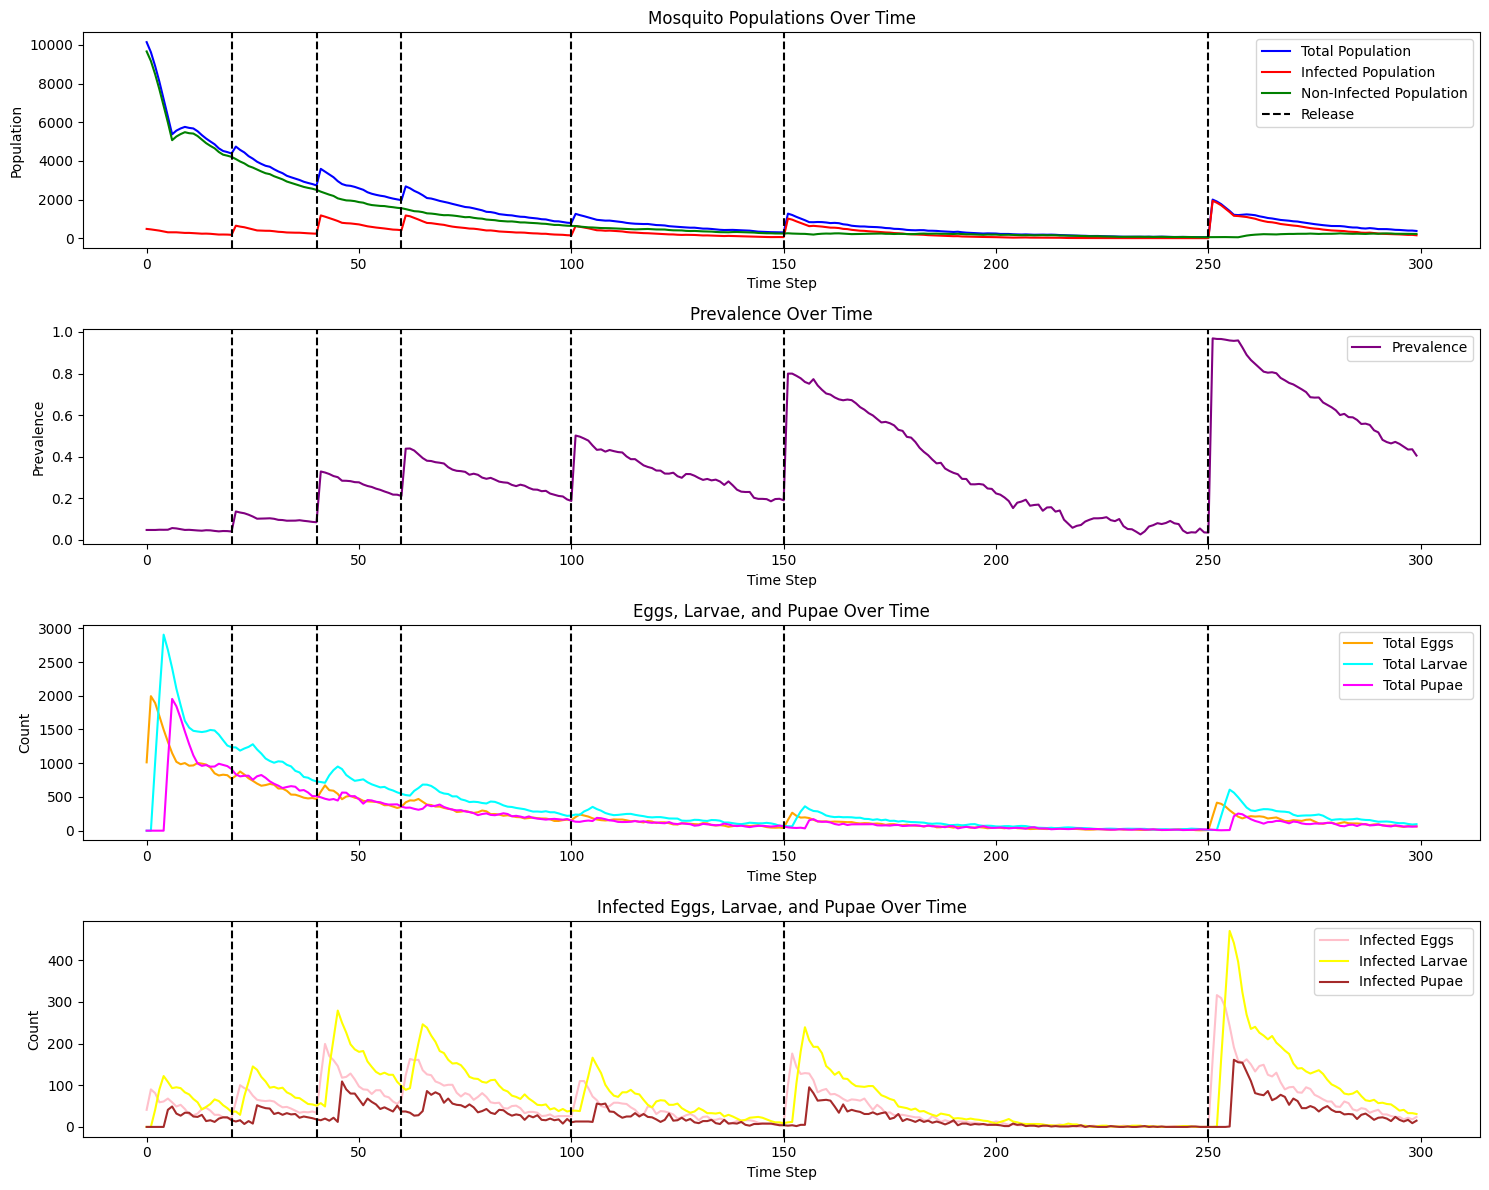

In [ ]:
# Plotting the results
plt.figure(figsize=(15, 12))

# Plot for total, infected, and non-infected mosquito populations
plt.subplot(4, 1, 1)
plt.plot(results['total_population'], label='Total Population', color='blue')
plt.plot(results['infected_population'], label='Infected Population', color='red')
plt.plot(results['non_infected_population'], label='Non-Infected Population', color='green')
for release_time in release_schedule.keys():
    plt.axvline(x=release_time, color='black', linestyle='--', label='Release' if release_time == 20 else '')
plt.title('Mosquito Populations Over Time')
plt.xlabel('Time Step')
plt.ylabel('Population')
plt.legend()

# Plot for prevalence
plt.subplot(4, 1, 2)
plt.plot(results['prevalence'], label='Prevalence', color='purple')
for release_time in release_schedule.keys():
    plt.axvline(x=release_time, color='black', linestyle='--')
plt.title('Prevalence Over Time')
plt.xlabel('Time Step')
plt.ylabel('Prevalence')
plt.legend()

# Plot for total eggs, larvae, and pupae
plt.subplot(4, 1, 3)
plt.plot(results['total_eggs'], label='Total Eggs', color='orange')
plt.plot(results['total_larvae'], label='Total Larvae', color='cyan')
plt.plot(results['total_pupae'], label='Total Pupae', color='magenta')
for release_time in release_schedule.keys():
    plt.axvline(x=release_time, color='black', linestyle='--')
plt.title('Eggs, Larvae, and Pupae Over Time')
plt.xlabel('Time Step')
plt.ylabel('Count')
plt.legend()

# Plot for infected eggs, larvae, and pupae
plt.subplot(4, 1, 4)
plt.plot(results['infected_eggs'], label='Infected Eggs', color='pink')
plt.plot(results['infected_larvae'], label='Infected Larvae', color='yellow')
plt.plot(results['infected_pupae'], label='Infected Pupae', color='brown')
for release_time in release_schedule.keys():
    plt.axvline(x=release_time, color='black', linestyle='--')
plt.title('Infected Eggs, Larvae, and Pupae Over Time')
plt.xlabel('Time Step')
plt.ylabel('Count')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# Display results
print(results.head(25))

    total_population  infected_population  non_infected_population  \
0              10131                  484                     9647   
1               9582                  452                     9130   
2               8891                  419                     8472   
3               8067                  372                     7695   
4               7177                  339                     6838   
5               6251                  288                     5963   
6               5394                  291                     5103   
7               5512                  289                     5223   
8               5614                  270                     5344   
9               5649                  266                     5383   
10              5591                  245                     5346   
11              5567                  233                     5334   
12              5504                  217                     5287   
13              5345